#Day 43 Unsupervised Model Using Clustering with Dendrogram

K-Means mengharuskan saya menentukan jumlah cluster di awal.

**Hierarchical Clustering** menawarkan pendekatan berbeda:
  - ia membangun "pohon keluarga" data (*dendrogram*) dari bawah ke atas, dan kita bisa memotong pohon itu di ketinggian mana pun untuk mendapatkan jumlah cluster yang kita mau.

> 🎯 **Tujuan Pembelajaran**
> - Memahami konsep *agglomerative* (penggabungan) hierarchical clustering.
> - Membuat & membaca **dendrogram** dengan `scipy.cluster.hierarchy`.
> - Menerapkan `AgglomerativeClustering` dari scikit-learn.
> - **Membandingkan** hasilnya dengan K-Means.


## About Dataset

Saya memakai kembali **Mall Customer Segmentation** agar bisa langsung membandingkan hasil hierarchical clustering dengan K-Means dari notebook sebelumnya.

- **Sumber:** [Kaggle — vjchoudhary7/customer-segmentation-tutorial-in-python](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python)
- **Jumlah data:** 200 baris × 5 kolom

| Kolom | Arti |
|-------|------|
| `Annual Income (k$)` | Pendapatan tahunan (ribu USD) |
| `Spending Score (1-100)` | Skor belanja |

## Import Library

- **scipy.cluster.hierarchy** → fungsi `linkage` (membangun pohon) & `dendrogram` (menggambar).
- **AgglomerativeClustering** → versi scikit-learn untuk memberi label cluster.
- **KMeans** → untuk pembanding.
- **StandardScaler** → standardisasi fitur.

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [32]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score

## Import Dataset

In [33]:
!pip install kaggle
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d vjchoudhary7/customer-segmentation-tutorial-in-python
!unzip customer-segmentation-tutorial-in-python.zip

mkdir: cannot create directory ‘/root/.kaggle’: File exists
cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python
License(s): other
customer-segmentation-tutorial-in-python.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  customer-segmentation-tutorial-in-python.zip
replace Mall_Customers.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
  inflating: Mall_Customers.csv      


## Early Exploration Dataset

In [34]:
df = pd.read_csv('Mall_Customers.csv')
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [36]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [37]:
print(f'Jumlah baris: {df.shape[0]}')
print(f'Jumlah kolom: {df.shape[1]}')

print(f'Missing Value: {df.isnull().sum().sum()}')
print(f'Duplicate Data: {df.duplicated().sum()}')

Jumlah baris: 200
Jumlah kolom: 5
Missing Value: 0
Duplicate Data: 0


**Interpretasi:**

- Tiap baris adalah satu pelanggan. Saya akan fokus pada dua fitur perilaku: **Annual Income** (kemampuan belanja) dan **Spending Score** (kecenderungan belanja).
- Pendapatan berkisar 15–137 ribu USD dan skor belanja merata 1–99 — variasi yang bagus untuk clustering.
- Dataset terdiri dari 200 baris dan 5 kolom
- Tidak terdapat Missing Value dan Data Duplicate

## Preparation & Standarization

Sama seperti K-Means, hierarchical clustering memakai **jarak**, jadi fitur perlu distandardisasi agar setara.

In [38]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f'Shape X_scaled: {X_scaled.shape}')
print(f'Rata rata setelah Scaled: {np.round(X_scaled.mean(axis=0), 2)}')
print(f'Standar deviasi setelah Scaled: {np.round(X_scaled.std(axis=0), 2)}')

Shape X_scaled: (200, 2)
Rata rata setelah Scaled: [-0. -0.]
Standar deviasi setelah Scaled: [1. 1.]


**Interpretasi:**
- Ukuran Data (200, 2): Dataset terdiri dari 200 baris sampel dan 2 kolom fitur.

- Rata-rata Menjadi 0 ([-0. -0.]): Titik pusat setiap fitur telah digeser ke angka nol.

- Standar Deviasi Menjadi 1 ([1. 1.]): Rentang penyebaran data pada tiap fitur telah diseragamkan menjadi satu.

Kesimpulan:
- Data telah berhasil distandarisasi menggunakan StandardScaler agar memiliki rata-rata 0 dan varians 1, yang merupakan tahap penting agar algoritma Machine Learning dapat memproses fitur secara adil tanpa ada yang mendominasi.

## Exploratory Data Analysis & Visualization

### a) Sebaran Data Awal

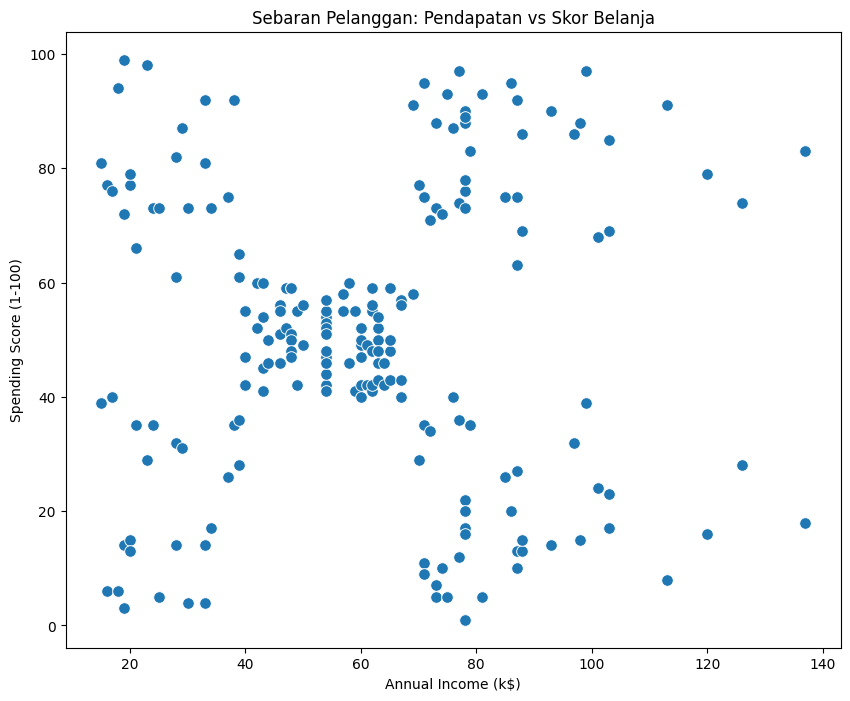

In [39]:
plt.figure(figsize=(10,8))
sns.scatterplot(x='Annual Income (k$)',
                y='Spending Score (1-100)',
                data=df,
                s=70)
plt.title('Sebaran Pelanggan: Pendapatan vs Skor Belanja')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()


### b) Membangun Dendogram

Apa itu Dendrogram?

  - Dendrogram adalah diagram berbentuk seperti pohon (akar ke atas/samping) yang menunjukkan proses penggabungan data satu per satu dari bawah sampai menjadi satu kelompok besar.

Sumbu-Y (Jarak Penggabungan):

  - Menunjukkan seberapa jauh jarak atau perbedaan saat dua kelompok digabungkan. Semakin tinggi letak garis penggabungannya, berarti kelompok tersebut semakin berbeda jauh.

Cara Memotong Pohon:
  - Garis horizontal yang paling panjang (atau celah kosong yang lebar sebelum digabung ke kelompok atasnya) adalah tempat paling ideal untuk "memotong" pohon. Potongan inilah yang menentukan berapa jumlah kelompok (cluster) terbaik yang terbentuk secara alami oleh data.

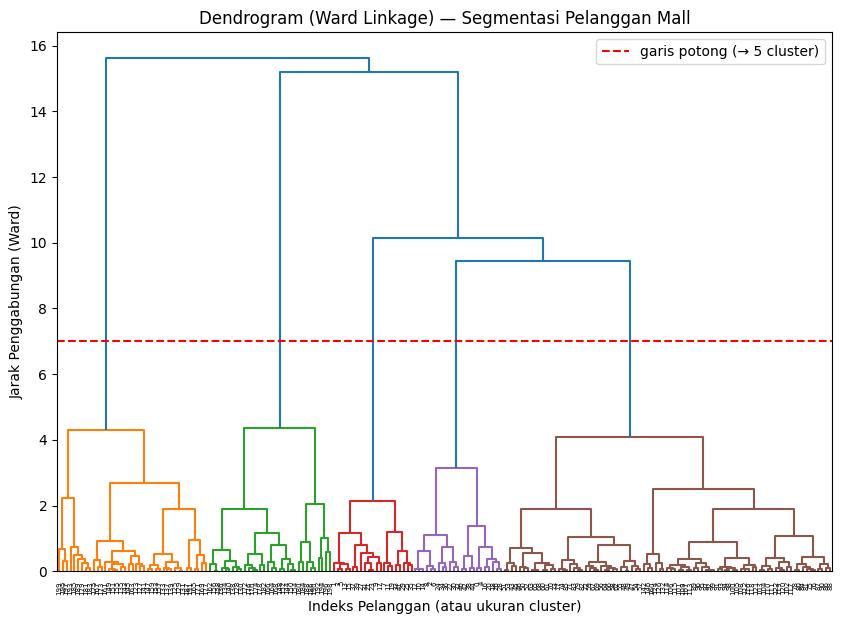

In [40]:
linked = linkage(X_scaled, 'ward')
label = fcluster(linked,
                 5,
                 criterion='maxclust')

plt.figure(figsize=(10, 7))

dendrogram(linked,
           truncate_mode=None,
           color_threshold=7)

plt.axhline(y=7,
            color="red",
            linestyle="--",
            label="garis potong (→ 5 cluster)")

plt.title("Dendrogram (Ward Linkage) — Segmentasi Pelanggan Mall")
plt.xlabel("Indeks Pelanggan (atau ukuran cluster)")
plt.ylabel("Jarak Penggabungan (Ward)")
plt.legend()
plt.show()

**Interpretasi:**
- Garis Potong Merah ($y=7$): Garis putus-putus merah memotong tepat 5 cabang utama dari pohon tersebut.   
- Warna Cabang: Setiap warna yang berbeda di bawah garis potong merepresentasikan 1 kelompok tersendiri (total ada 5 kelompok: oranye, hijau, merah, ungu, dan cokelat).   

Kesimpulan:
- Diagram ini semakin memperkuat validasi sebelumnya bahwa pembagian data pelanggan menjadi 5 klaster adalah pilihan yang paling alami dan optimal berdasarkan jarak penggabungannya.


### c) Memberi Label Cluster dengan Agglomerative Clustering

Kini saya pakai versi scikit-learn untuk benar-benar memberi label cluster (5 cluster, Ward).

In [41]:
agg = AgglomerativeClustering(n_clusters=5,
                              metric='euclidean',
                              linkage='ward')

df["Cluster_agg"] = agg.fit_predict(X_scaled)

In [42]:
df.head(2)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster_agg
0,1,Male,19,15,39,4
1,2,Male,21,15,81,3


In [43]:
print(f'Jumlah cluster: {df["Cluster_agg"].nunique()}')
print(f'Cluster: {df["Cluster_agg"].unique()}')

print(f'Jumlah pelanggan dalam cluster 0: {df[df["Cluster_agg"] == 0].shape[0]}')
print(f'Jumlah pelanggan dalam cluster 1: {df[df["Cluster_agg"] == 1].shape[0]}')
print(f'Jumlah pelanggan dalam cluster 2: {df[df["Cluster_agg"] == 2].shape[0]}')
print(f'Jumlah pelanggan dalam cluster 3: {df[df["Cluster_agg"] == 3].shape[0]}')
print(f'Jumlah pelanggan dalam cluster 4: {df[df["Cluster_agg"] == 4].shape[0]}')

Jumlah cluster: 5
Cluster: [4 3 2 1 0]
Jumlah pelanggan dalam cluster 0: 32
Jumlah pelanggan dalam cluster 1: 39
Jumlah pelanggan dalam cluster 2: 85
Jumlah pelanggan dalam cluster 3: 21
Jumlah pelanggan dalam cluster 4: 23


Penerapan Model:

- Data distandarisasi (X_scaled) dikelompokkan menggunakan algoritma Agglomerative Clustering dengan metode Ward menjadi tepat 5 klaster.

Distribusi Jumlah Anggota per Klaster:

- Klaster 0: Berisi 32 pelanggan.

- Klaster 1: Berisi 39 pelanggan.

- Klaster 2: Merupakan kelompok terbesar yang berisi 85 pelanggan.

- Klaster 3: Berisi 21 pelanggan.

- Klaster 4: Berisi 23 pelanggan.

Total Keseluruhan:
- Jika ditotal (32 + 39 + 85 + 21 + 23), jumlahnya pas 200 pelanggan, yang berarti seluruh data berhasil dikelompokkan ke dalam masing-masing klaster tanpa ada yang tertinggal.

## Comparisson with KMeans

Apakah dua algoritma berbeda menghasilkan segmentasi serupa?

- Saya akan bandingkan visual, **Silhouette Score**, dan **Adjusted Rand Index (ARI)**
- ARI mengukur kemiripan dua pelabelan (1 = identik, ~0 = acak)

In [44]:
k_mn = KMeans(n_clusters=5,
              random_state=42,
              n_init=10)
df["KMeans_cluster"] = k_mn.fit_predict(X_scaled)

In [45]:
sil_agg = silhouette_score(X_scaled, df["Cluster_agg"])
sil_km = silhouette_score(X_scaled, df["KMeans_cluster"])

ari_agg = adjusted_rand_score(df["Cluster_agg"], df["KMeans_cluster"])

print(f'Silhouette Score (Agglomerative): {sil_agg:.4f}')
print(f'Silhouette Score (KMeans): {sil_km:.4f}')
print(f'Adjusted Rand Index (ARI): {ari_agg:.4f}')

Silhouette Score (Agglomerative): 0.5538
Silhouette Score (KMeans): 0.5547
Adjusted Rand Index (ARI): 0.9420


**Interpretasi Hasil Perbandingan:**

1. **Silhouette Score**:
   - **Agglomerative Clustering**: `0.5538`
   - **K-Means**: `0.5547`
   - K-Means memiliki skor yang sedikit lebih tinggi, namun perbedaannya sangat tipis. Kedua model menunjukkan struktur pengelompokan yang cukup solid dan terpisah dengan baik.

2. **Adjusted Rand Index (ARI)**: `0.9420`
   - Nilai ARI mencapai **94.2%**, yang menandakan tingkat kesamaan (agreement) yang sangat tinggi antara kedua algoritma. Kedua pendekatan menghasilkan segmentasi pelanggan yang hampir serupa meskipun bekerja dengan cara yang berbeda.

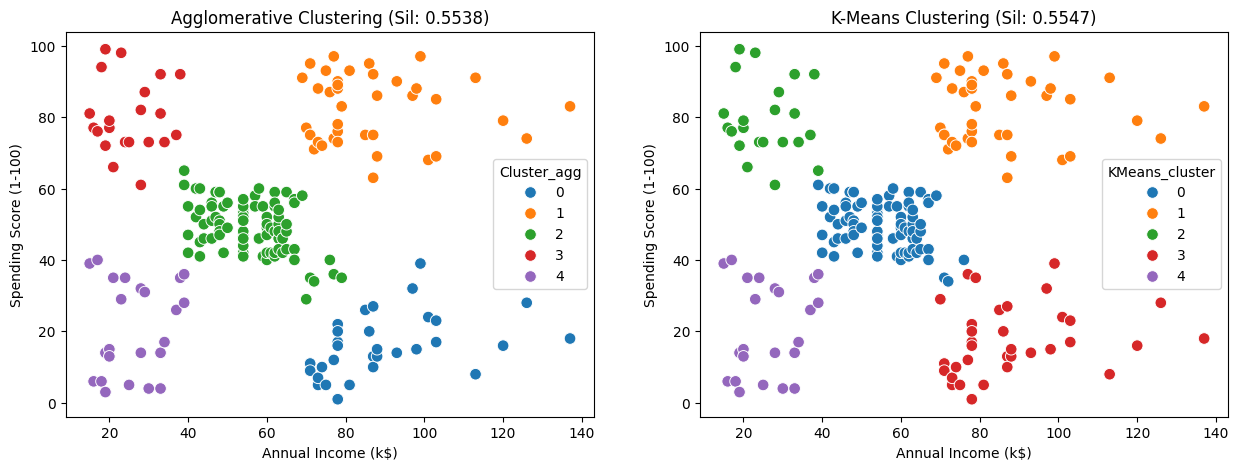

In [53]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

sns.scatterplot(x='Annual Income (k$)',
                y='Spending Score (1-100)',
                data=df,
                hue='Cluster_agg',
                ax=ax[0],
                s=70,
                palette="tab10")
ax[0].set_title(f'Agglomerative Clustering (Sil: {sil_agg:.4f})')

sns.scatterplot(x='Annual Income (k$)',
                y='Spending Score (1-100)',
                data=df,
                hue='KMeans_cluster',
                ax=ax[1],
                s=70,
                palette="tab10")
ax[1].set_title(f'K-Means Clustering (Sil: {sil_km:.4f})')

plt.show()

**Interpretasi:**

Kesimpulan:
  - Hasil visual ini memperkuat nilai ARI 94.2% sebelumnya—menunjukkan bahwa kedua algoritma menghasilkan pola segmentasi pelanggan yang pada dasarnya sama persis.


### 🌟 Kesimpulan Utama (Conclusion)

1. **Kesamaan Hasil yang Luar Biasa (High Consistency)**:
   - Berdasarkan nilai **Adjusted Rand Index (ARI) sebesar 94.2%**, kedua algoritma menghasilkan pembagian kelompok (cluster) yang hampir identik secara spasial.
   - Baik metode berbasis hierarki (*Agglomerative Clustering*) maupun berbasis pusat massa (*K-Means*) mendeteksi **5 kelompok alami** pelanggan yang sama dari data pendapatan dan skor belanja.

2. **Kualitas Klaster yang Setara**:
   - **Silhouette Score** kedua model berada di kisaran **0.55** (K-Means: 0.5547 vs Agglomerative: 0.5538). Ini membuktikan batas antar klaster cukup tegas dan titik-titik di dalam klaster berdekatan secara optimal.

---

### 💡 Insight Strategi Bisnis (Business Insights)

Dari 5 kelompok pelanggan yang terbentuk, berikut adalah segmentasi dan strategi pendekatan bisnis yang dapat direkomendasikan:

* **Cluster 1 (Target Utama / *Stars* - Pendapatan Tinggi & Belanja Tinggi)**:
  * *Karakteristik*: Pelanggan dengan daya beli tinggi dan sangat aktif berbelanja.
  * *Strategi*: Tawarkan program loyalitas VIP, peluncuran produk eksklusif/terbatas (*limited edition*), dan penawaran personal bernilai tinggi.

* **Cluster 2 (Potensial / *Targets* - Pendapatan Rendah & Belanja Tinggi)**:
  * *Karakteristik*: Pelanggan yang sangat konsumtif meskipun memiliki pendapatan terbatas.
  * *Strategi*: Berikan diskon khusus, promo cicilan, atau program poin (*reward points*) untuk menjaga ketertarikan mereka tanpa membebani keuangan secara ekstrem.

* **Cluster 3 (Hemat / *Carefuls* - Pendapatan Tinggi & Belanja Rendah)**:
  * *Karakteristik*: Pelanggan yang kaya tetapi sangat berhati-hati dalam membelanjakan uangnya.
  * *Strategi*: Lakukan kampanye pemasaran berbasis nilai fungsional produk, jaminan kualitas, atau penawaran produk investasi/premium yang memiliki nilai guna jangka panjang.

* **Cluster 4 (Rata-rata / *Standard* - Pendapatan Sedang & Belanja Sedang)**:
  * *Karakteristik*: Kelompok mayoritas (paling padat di bagian tengah visualisasi).
  * *Strategi*: Promosikan barang-barang kebutuhan sehari-hari dengan penawaran bundel (*bundle deals*) menarik untuk meningkatkan volume transaksi bulanan.

* **Cluster 5 (Konservatif / *Sensibles* - Pendapatan Rendah & Belanja Rendah)**:
  * *Karakteristik*: Pelanggan yang hemat dengan pendapatan yang juga rendah.
  * *Strategi*: Fokus pada promosi produk esensial dengan harga murah atau diskon cuci gudang.